# IMS 4채널 특징 추출 + 이상 감지 (PCA · Autoencoder) + Health Index
**목표**: IMS Set 2의 베어링 4개 모두에서 특징을 뽑고, **초기 정상 구간만으로 학습**한 이상 감지 모델로 Health Index(0~100)를 만들어 기존 마할라노비스 방식과 비교합니다.

| 단계 | 내용 |
|---|---|
| 1~2 | 환경 설정, IMS 데이터를 Colab 로컬로 복사 |
| 3~4 | 특징 추출 함수, **4채널** 특징 추출 → `ims_features_4ch.parquet` |
| 5 | 전처리: 베어링별 정상 구간 기준 z-score |
| 6 | 기준선: 마할라노비스, PCA 재구성 오차 |
| 7 | Autoencoder (PyTorch) |
| 8 | 점수 → Health Index 변환 + 평활 |
| 9~10 | 방법별 지표 비교, 그래프 |
| 11 | 서버(VS Code)에서 쓸 모델/설정 저장 |

**Set 2 구성**: 베어링 1이 실험 끝(약 164시간)에 외륜 결함으로 고장. 베어링 2~4는 **고장 기록이 없음** → 이상 감지가 이 3개를 이상이라고 오판하는지(오탐)도 함께 확인합니다.

## 1. 환경 설정

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from pathlib import Path
from datetime import datetime
from scipy import signal, stats
from scipy.fft import rfft, rfftfreq

BASE = Path('/content/drive/MyDrive/pdm_project')
(BASE / 'features').mkdir(parents=True, exist_ok=True)
(BASE / 'models').mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

Mounted at /content/drive
device: cuda


## 2. IMS 데이터를 Colab 로컬 디스크로 복사
(Drive에서 작은 파일 984개를 직접 읽으면 느립니다. 특징 파일이 이미 있으면 이 단계는 건너뛰어도 됩니다.)

In [ ]:
FEAT_PATH = BASE / 'features' / 'ims_features_4ch.parquet'

if not FEAT_PATH.exists():
    !mkdir -p /content/ims_local
    !cp -r "/content/drive/MyDrive/pdm_project/ims/2nd_test" /content/ims_local/

    def find_dir_with_most_files(root, dirname):
        cands = [p for p in Path(root).rglob(dirname) if p.is_dir()]
        cands = [p for p in cands if any(q.is_file() for q in p.iterdir())]
        return max(cands, key=lambda p: sum(q.is_file() for q in p.iterdir()))

    ims_dir = find_dir_with_most_files('/content/ims_local', '2nd_test')
    files = sorted(p for p in ims_dir.iterdir() if p.is_file())
    print(ims_dir, len(files), '개 (984개여야 정상)')
else:
    print('특징 파일이 이미 있습니다 → 4번 셀에서 불러옵니다:', FEAT_PATH)

특징 파일이 이미 있습니다 → 4번 셀에서 불러옵니다: /content/drive/MyDrive/pdm_project/features/ims_features_4ch.parquet


## 3. 특징 추출 함수 (이전 노트북과 동일)

In [ ]:
import numpy as np, pandas as pd
from scipy import signal, stats
from scipy.fft import rfft, rfftfreq

def bearing_freqs(shaft_hz, n, d, D, theta_deg=0.0):
    """결함 주파수(Hz). n=볼/롤러 수, d=볼 지름, D=피치 지름."""
    r = d / D * np.cos(np.radians(theta_deg))
    return {
        'BPFO': n / 2 * shaft_hz * (1 - r),
        'BPFI': n / 2 * shaft_hz * (1 + r),
        'BSF' : D / (2 * d) * shaft_hz * (1 - r**2),
        'FTF' : shaft_hz / 2 * (1 - r),
    }

def time_features(x):
    rms = np.sqrt(np.mean(x**2)); peak = np.max(np.abs(x)); mabs = np.mean(np.abs(x))
    return {
        'mean': x.mean(), 'std': x.std(), 'rms': rms, 'peak': peak,
        'p2p': x.max() - x.min(),
        'kurtosis': stats.kurtosis(x), 'skew': stats.skew(x),
        'crest': peak / rms, 'shape': rms / mabs, 'impulse': peak / mabs,
    }

def amp_spectrum(x, fs):
    w = signal.windows.hann(len(x))                  # Hanning 윈도우
    X = np.abs(rfft((x - x.mean()) * w)) * 2 / w.sum()
    return rfftfreq(len(x), 1 / fs), X

def band_peak(f, X, f0, tol_hz):
    m = (f >= f0 - tol_hz) & (f <= f0 + tol_hz)
    return float(X[m].max()) if m.any() else 0.0

def freq_features(x, fs, shaft_hz, fault, prefix='', n_harm=2, tol_ratio=0.03):
    f, X = amp_spectrum(x, fs)
    df = f[1] - f[0]
    P = X**2; Pn = P / (P.sum() + 1e-18)
    out = {
        f'{prefix}spec_entropy' : float(-(Pn * np.log(Pn + 1e-18)).sum()),
        f'{prefix}spec_centroid': float((f * Pn).sum()),
        f'{prefix}spec_peak_hz' : float(f[np.argmax(X)]),
    }
    targets = {'1X': shaft_hz, '2X': 2 * shaft_hz, '3X': 3 * shaft_hz}
    for name in ['BPFO', 'BPFI', 'BSF']:
        for h in range(1, n_harm + 1):
            targets[f'{name}_h{h}'] = fault[name] * h
    for k, f0 in targets.items():
        out[f'{prefix}{k}'] = band_peak(f, X, f0, max(f0 * tol_ratio, 2 * df))
    return out

def envelope_features(x, fs, fault, band=(2000, 5000), prefix='env_', n_harm=2, tol_ratio=0.03):
    nyq = fs / 2
    hi = min(band[1], nyq * 0.95)
    sos = signal.butter(4, [band[0] / nyq, hi / nyq], btype='band', output='sos')
    env = np.abs(signal.hilbert(signal.sosfiltfilt(sos, x)))
    f, X = amp_spectrum(env, fs)
    df = f[1] - f[0]
    out = {}
    for name in ['BPFO', 'BPFI', 'BSF']:
        for h in range(1, n_harm + 1):
            f0 = fault[name] * h
            out[f'{prefix}{name}_h{h}'] = band_peak(f, X, f0, max(f0 * tol_ratio, 2 * df))
    return out

def extract_all(x, fs, shaft_hz, fault, env_band):
    x = np.asarray(x, dtype=float)
    feats = time_features(x)
    feats.update(freq_features(x, fs, shaft_hz, fault))
    feats.update(envelope_features(x, fs, fault, band=env_band))
    return feats

def sliding_windows(x, size, hop):
    for i in range(0, len(x) - size + 1, hop):
        yield i, x[i:i + size]

## 4. 4채널 특징 추출
파일 1개를 한 번만 읽고 열 4개(= 베어링 1~4)를 모두 처리합니다.
결과는 `ims_features_4ch.parquet`로 저장되어서 다음에는 바로 불러온다.


In [ ]:
IMS_FS = 20_480
IMS_SHAFT = 2000 / 60
IMS_FAULT = bearing_freqs(IMS_SHAFT, n=16, d=0.331, D=2.815, theta_deg=15.17)
ENV_BAND = (2000, 9000)
print({k: round(float(v), 1) for k, v in IMS_FAULT.items()})

def ims_time(name):
    y, mo, d, h, mi, s = map(int, re.findall(r'\d+', name)[:6])
    return datetime(y, mo, d, h, mi, s)

if FEAT_PATH.exists():
    df = pd.read_parquet(FEAT_PATH)
else:
    t0 = ims_time(files[0].name)
    rows = []
    for i, p in enumerate(files):
        arr = pd.read_csv(p, sep='\t', header=None).values            # (20480, 4)
        elapsed = (ims_time(p.name) - t0).total_seconds() / 3600
        for ch in range(arr.shape[1]):
            f = extract_all(arr[:, ch], IMS_FS, IMS_SHAFT, IMS_FAULT, ENV_BAND)
            f.update(bearing=ch + 1, file_idx=i, elapsed_h=elapsed)
            rows.append(f)
        if (i + 1) % 200 == 0:
            print(f'{i + 1} / {len(files)}')
    df = pd.DataFrame(rows)
    df.to_parquet(FEAT_PATH, index=False)

print(df.shape, '| 베어링:', sorted(df['bearing'].unique()), '| 파일 수:', df['file_idx'].nunique())
df.head()

{'BPFO': 236.4, 'BPFI': 296.9, 'BSF': 139.9, 'FTF': 14.8}
(3936, 31) | 베어링: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)] | 파일 수: 984


,mean,std,rms,peak,p2p,kurtosis,skew,crest,shape,impulse,...,BSF_h2,env_BPFO_h1,env_BPFO_h2,env_BPFI_h1,env_BPFI_h2,env_BSF_h1,env_BSF_h2,bearing,file_idx,elapsed_h
0,-0.010196,0.073475,0.074179,0.454,0.840,0.628763,0.083993,6.120331,1.271660,7.782979,...,0.001509,0.003543,0.003974,0.002842,0.002649,0.002717,0.003319,1,0,0.000000
1,-0.012695,0.090053,0.090944,0.513,0.977,0.506801,0.126915,5.640841,1.266071,7.141704,...,0.002222,0.006515,0.004646,0.002738,0.002827,0.003402,0.002509,2,0,0.000000
2,-0.014541,0.108434,0.109404,1.023,1.934,3.213075,0.204840,9.350652,1.314254,12.289132,...,0.002984,0.006271,0.004449,0.006296,0.006590,0.003643,0.012502,3,0,0.000000
3,-0.010026,0.053166,0.054103,0.264,0.457,0.065959,-0.022080,4.879539,1.256323,6.130277,...,0.001810,0.002107,0.001593,0.002105,0.002109,0.001504,0.002692,4,0,0.000000
4,-0.002585,0.075338,0.075382,0.388,0.757,0.648291,0.052142,5.147086,1.277742,6.576647,...,0.001664,0.004028,0.003306,0.002659,0.002528,0.002467,0.002434,1,1,0.166667


## 5. 전처리: 베어링별 정상 구간 기준 z-score
- **정상 구간 = 처음 25% 파일(약 41시간)**. 베어링 1의 열화가 약 89시간부터 보이므로 안전한 구간입니다.
- 센서/설치 위치마다 값의 크기가 다르므로 **베어링마다 자기 정상 구간의 평균·표준편차**로 정규화합니다. 그 뒤 4개 베어링 데이터를 합쳐서 하나의 모델을 학습합니다.
- 진폭 특징은 한쪽으로 치우쳐 있어서 부호 보존 로그(`sign(x)·log1p(|x|)`)를 먼저 적용합니다.
- 정상 구간 안에서도 **앞 80%로 학습, 뒤 20%는 검증**(시간 순서 유지)합니다.

In [ ]:
META = ['bearing', 'file_idx', 'elapsed_h']
feat_all = [c for c in df.columns if c not in META]
NORMAL_FRAC = 0.25
Z_CLIP = 50.0

def slog(x):
    return np.sign(x) * np.log1p(np.abs(x))

n_files = int(df['file_idx'].max()) + 1
n_normal = int(n_files * NORMAL_FRAC)
n_train = int(n_normal * 0.8)
is_normal = (df['file_idx'] < n_normal).values
is_train  = (df['file_idx'] < n_train).values
is_val    = is_normal & ~is_train
print(f'정상 구간: 파일 0~{n_normal - 1} ({df.loc[is_normal, "elapsed_h"].max():.1f}시간) | 학습 {is_train.sum()}행, 검증 {is_val.sum()}행')

Xs = slog(df[feat_all].values.astype(float))
bearings = sorted(df['bearing'].unique())

# 정상 구간에서 변동이 없는 특징은 제외
sd_min = np.min([Xs[(df['bearing'] == b).values & is_normal].std(0) for b in bearings], axis=0)
keep = sd_min > 1e-8
feat_cols = [c for c, k in zip(feat_all, keep) if k]
Xs = Xs[:, keep]
print(f'특징 {len(feat_all)}개 중 {len(feat_cols)}개 사용 (제외: {[c for c, k in zip(feat_all, keep) if not k]})')

mu, sd = {}, {}
Z = np.empty_like(Xs)
for b in bearings:
    m = (df['bearing'] == b).values
    base = Xs[m & is_normal]
    mu[b], sd[b] = base.mean(0), base.std(0) + 1e-8
    Z[m] = (Xs[m] - mu[b]) / sd[b]
Z = np.clip(Z, -Z_CLIP, Z_CLIP)
D = Z.shape[1]
print('Z shape:', Z.shape)

정상 구간: 파일 0~245 (40.8시간) | 학습 784행, 검증 200행
특징 28개 중 28개 사용 (제외: [])
Z shape: (3936, 28)


## 6. 기준선 방법 두 가지
- **마할라노비스 거리²**: 정상 구간 분포에서 얼마나 벗어났는지 (이전 노트북에서 쓴 방식을 같은 전처리로 다시 계산)
- **PCA 재구성 오차(SPE)**: 정상 구간으로 주성분(분산 95%)을 학습하고, 주성분으로 복원했을 때 남는 오차. 정상 패턴으로 설명되지 않는 부분이 클수록 이상입니다.

In [ ]:
from sklearn.decomposition import PCA

Znorm, Ztr = Z[is_normal], Z[is_train]

mu0 = Znorm.mean(0)
cov_inv = np.linalg.pinv(np.cov(Znorm.T) + 1e-3 * np.eye(D))
def maha2(Zx):
    d = Zx - mu0
    return np.einsum('ij,jk,ik->i', d, cov_inv, d)            # 거리의 제곱

pca = PCA(n_components=0.95, svd_solver='full').fit(Ztr)
def pca_spe(Zx):
    rec = pca.inverse_transform(pca.transform(Zx))
    return ((Zx - rec) ** 2).mean(1)

print('PCA 주성분 수:', pca.n_components_, '/', D)

PCA 주성분 수: 21 / 28


## 7. Autoencoder (PyTorch)
정상 구간 데이터만으로 `입력 → 병목(4차원) → 복원`을 학습합니다. 정상 패턴은 잘 복원하고, 처음 보는 이상 패턴은 복원하지 못해 **재구성 오차가 커집니다**. 이 오차가 이상 점수입니다.

In [ ]:
class AE(nn.Module):
    def __init__(self, d, latent=4):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d, 16), nn.ReLU(), nn.Linear(16, 8), nn.ReLU(), nn.Linear(8, latent))
        self.dec = nn.Sequential(nn.Linear(latent, 8), nn.ReLU(), nn.Linear(8, 16), nn.ReLU(), nn.Linear(16, d))
    def forward(self, x):
        return self.dec(self.enc(x))

@torch.no_grad()
def ae_score(model, X):
    model.eval()
    x = torch.tensor(X, dtype=torch.float32, device=device)
    return ((model(x) - x) ** 2).mean(1).cpu().numpy()

def train_autoencoder(Xtr, Xva, epochs=400, patience=40, lr=1e-3, seed=SEED):
    torch.manual_seed(seed)
    model = AE(Xtr.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    xtr = torch.tensor(Xtr, dtype=torch.float32, device=device)
    best, best_state, bad = 1e18, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(xtr), device=device)
        for i in range(0, len(xtr), 64):
            xb = xtr[perm[i:i + 64]]
            opt.zero_grad(); loss = ((model(xb) - xb) ** 2).mean(); loss.backward(); opt.step()
        val = float(ae_score(model, Xva).mean())
        if val < best:
            best, bad = val, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if ep % 25 == 0 or ep == 1:
            print(f'ep {ep:>3}  val_mse={val:.4f}')
        if bad >= patience:
            print(f'early stop @ {ep}'); break
    model.load_state_dict(best_state)
    print('best val mse:', round(best, 4))
    return model

ae = train_autoencoder(Z[is_train], Z[is_val])

ep   1  val_mse=0.9605
ep  25  val_mse=0.7260
ep  50  val_mse=0.6672
ep  75  val_mse=0.6577
ep 100  val_mse=0.6468
ep 125  val_mse=0.6249
ep 150  val_mse=0.6196
ep 175  val_mse=0.6178
ep 200  val_mse=0.6169
ep 225  val_mse=0.6159
early stop @ 232
best val mse: 0.6142


## 8. 점수 → Health Index (0~100)
- **임계값**: 정상 구간 점수의 99번째 백분위수. 점수가 임계값 이하면 정상입니다.
- **HI 변환**: `비율 = 점수 / 임계값`일 때 `HI = 100 × (1 − log10(비율) / log10(100))`
  → 비율 1 이하 = 100, 비율 10 = 50, 비율 100 이상 = 0. 상수(100)는 데이터에서 구한 값이 아니라 **고정값**이라 고장 시점 정보를 쓰지 않습니다.
- **평활**: 5개 파일 이동 중앙값(순간적인 튐 제거). 단조 감소 표시용으로 `cummin`(지금까지의 최저값)도 같이 만듭니다.
- **융합(Fusion)**: AE와 PCA 비율의 기하평균.

In [ ]:
R_MAX = 100.0
scores = {
    'Mahalanobis': maha2(Z),
    'PCA-SPE': pca_spe(Z),
    'Autoencoder': ae_score(ae, Z),
}
thr = {m: float(np.percentile(s[is_normal], 99)) for m, s in scores.items()}
ratio = {m: np.maximum(scores[m] / thr[m], 1e-12) for m in scores}
ratio['Fusion(AE+PCA)'] = np.exp(0.5 * (np.log(ratio['Autoencoder']) + np.log(ratio['PCA-SPE'])))
methods = list(ratio)

def to_hi(r):
    return 100.0 * (1.0 - np.clip(np.log10(np.maximum(r, 1.0)) / np.log10(R_MAX), 0.0, 1.0))

res = df[META].copy()
for m in methods:
    res[f'{m}|ratio'] = ratio[m]
    res[f'{m}|hi'] = to_hi(ratio[m])
    res[f'{m}|hi_s'] = res.groupby('bearing')[f'{m}|hi'].transform(lambda s: s.rolling(5, min_periods=1).median())
    res[f'{m}|hi_mono'] = res.groupby('bearing')[f'{m}|hi_s'].cummin()

print('임계값:', {m: round(v, 4) for m, v in thr.items()})
res[res['bearing'] == 1].tail()

임계값: {'Mahalanobis': 55.1684, 'PCA-SPE': 0.1846, 'Autoencoder': 1.2666}


,bearing,file_idx,elapsed_h,Mahalanobis|ratio,Mahalanobis|hi,Mahalanobis|hi_s,Mahalanobis|hi_mono,PCA-SPE|ratio,PCA-SPE|hi,PCA-SPE|hi_s,PCA-SPE|hi_mono,Autoencoder|ratio,Autoencoder|hi,Autoencoder|hi_s,Autoencoder|hi_mono,Fusion(AE+PCA)|ratio,Fusion(AE+PCA)|hi,Fusion(AE+PCA)|hi_s,Fusion(AE+PCA)|hi_mono
3916,1,979,163.166667,6328.989753,0.0,0.0,0.0,489.239412,0.000000,0.0,0.0,588.444580,0.0,0.0,0.0,536.554117,0.0,0.0,0.0
3920,1,980,163.333333,2872.087051,0.0,0.0,0.0,321.476738,0.000000,0.0,0.0,344.057587,0.0,0.0,0.0,332.575542,0.0,0.0,0.0
3924,1,981,163.500000,3810.196306,0.0,0.0,0.0,382.511492,0.000000,0.0,0.0,346.537506,0.0,0.0,0.0,364.080444,0.0,0.0,0.0
3928,1,982,163.666667,379.030350,0.0,0.0,0.0,399.727218,0.000000,0.0,0.0,150.727264,0.0,0.0,0.0,245.458318,0.0,0.0,0.0
3932,1,983,163.833333,199.503352,0.0,0.0,0.0,91.860873,1.843472,0.0,0.0,148.216782,0.0,0.0,0.0,116.684709,0.0,0.0,0.0


## 9. 방법별 비교 (표)
- **Spearman**: 베어링 1에서 시간과 HI의 순위 상관(−1에 가까울수록 일관되게 감소)
- **단조성**: `|증가 횟수 − 감소 횟수| / (증가+감소 횟수)` — 값이 변하지 않은 구간은 제외 (1에 가까울수록 한 방향)
- **첫 경보**: 평활 HI가 60 미만으로 3회 연속 내려간 첫 시점과 고장까지 남은 시간(리드타임)
- **오탐률(베어링 2~4)**: 고장이 없는 베어링에서 HI가 60 미만이었던 비율 (낮을수록 좋음)

In [ ]:
def monotonicity(x):
    d = np.diff(x)
    d = d[d != 0]                          # 100으로 고정된 정상 구간(변화 없음)은 제외
    return float(abs((d > 0).sum() - (d < 0).sum()) / max(len(d), 1))

def first_alarm(hi, t, level=60.0, k=3):
    below = hi < level
    for i in range(len(hi) - k + 1):
        if below[i:i + k].all():
            return t[i]
    return None

rows = []
b1 = res[res['bearing'] == 1].sort_values('file_idx')
others = res[res['bearing'] != 1]
t, t_end = b1['elapsed_h'].values, b1['elapsed_h'].max()
for m in methods:
    hi_s = b1[f'{m}|hi_s'].values
    ta = first_alarm(hi_s, t)
    rows.append({
        '방법': m,
        'Spearman': round(float(stats.spearmanr(t, hi_s).correlation), 3),
        '단조성': round(monotonicity(hi_s), 3),
        '첫 경보(h)': None if ta is None else round(float(ta), 1),
        '리드타임(h)': None if ta is None else round(float(t_end - ta), 1),
        '오탐률(베어링2~4)': round(float((others[f'{m}|hi_s'] < 60).mean()), 4),
        '정상구간 최저 HI(B1)': round(float(b1.loc[b1['file_idx'] < n_normal, f'{m}|hi_s'].min()), 1),
    })
summary = pd.DataFrame(rows).set_index('방법')
summary

,Spearman,단조성,첫 경보(h),리드타임(h),오탐률(베어링2~4),정상구간 최저 HI(B1)
방법,,,,,,
Mahalanobis,-0.885,0.398,90.3,73.5,0.1274,71.5
PCA-SPE,-0.883,0.148,96.2,67.7,0.1189,94.3
Autoencoder,-0.890,0.459,90.0,73.8,0.1274,100.0
Fusion(AE+PCA),-0.892,0.360,91.5,72.3,0.1297,97.3


## 10. 그래프 (베어링 1 = 빨강, 2~4 = 회색)
1: 고장
2~4 : 고장 없음



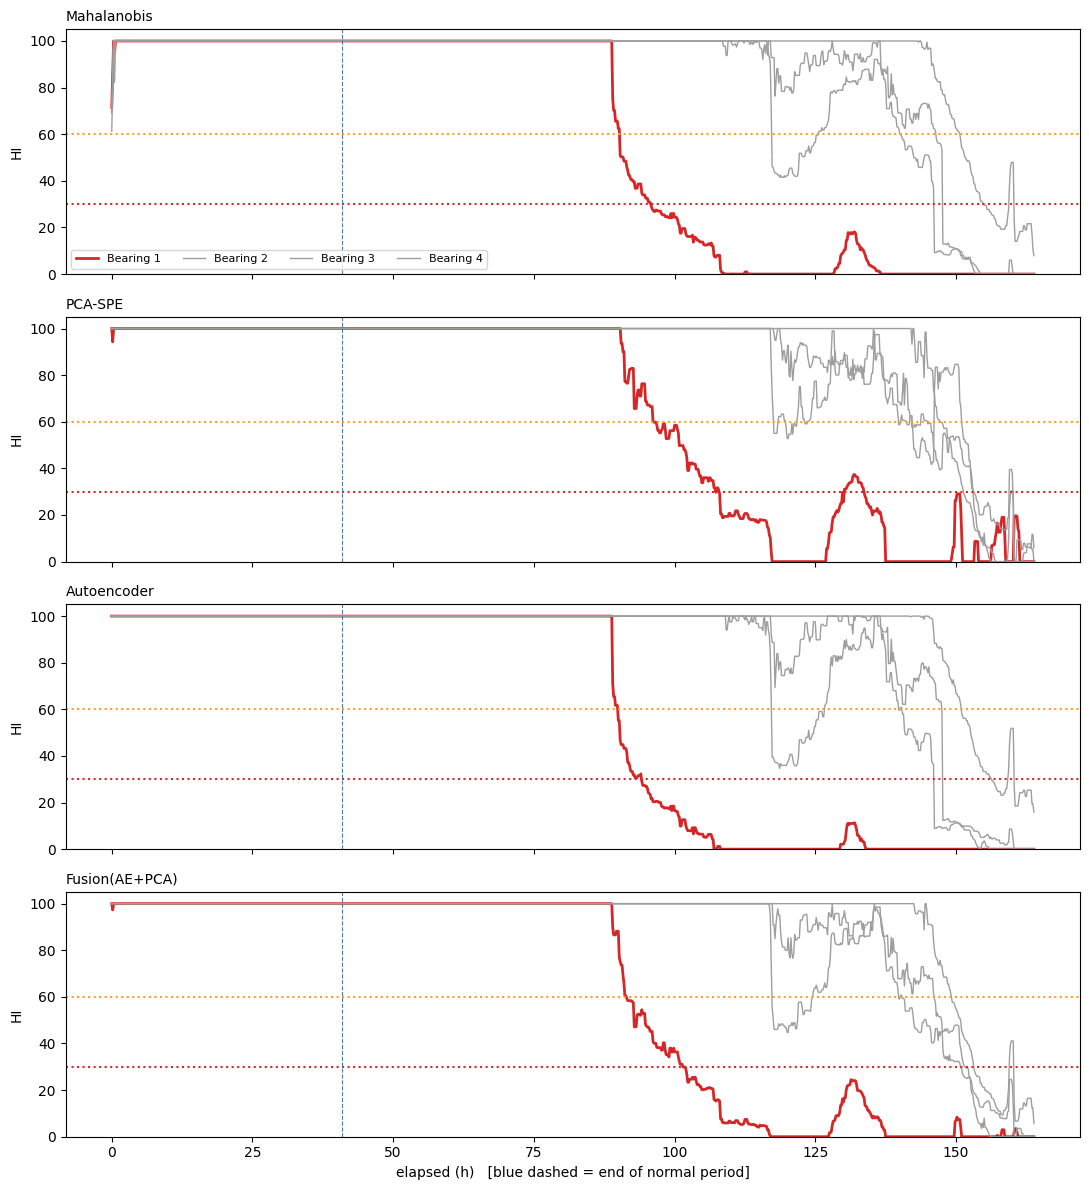

In [ ]:
fig, axes = plt.subplots(len(methods), 1, figsize=(11, 3 * len(methods)), sharex=True)
for ax, m in zip(axes, methods):
    for b in bearings:
        r = res[res['bearing'] == b]
        ax.plot(r['elapsed_h'], r[f'{m}|hi_s'], color='#d62728' if b == 1 else '#9e9e9e',
                lw=2 if b == 1 else 1, label=f'Bearing {b}')
    ax.axhline(60, ls=':', color='#ff9f1c'); ax.axhline(30, ls=':', color='#d62728')
    ax.axvline(df.loc[is_normal, 'elapsed_h'].max(), ls='--', color='#4c78a8', lw=0.8)
    ax.set_ylim(0, 105); ax.set_ylabel('HI'); ax.set_title(m, loc='left', fontsize=10)
axes[0].legend(ncol=4, fontsize=8, loc='lower left')
axes[-1].set_xlabel('elapsed (h)   [blue dashed = end of normal period]')
plt.tight_layout(); plt.show()

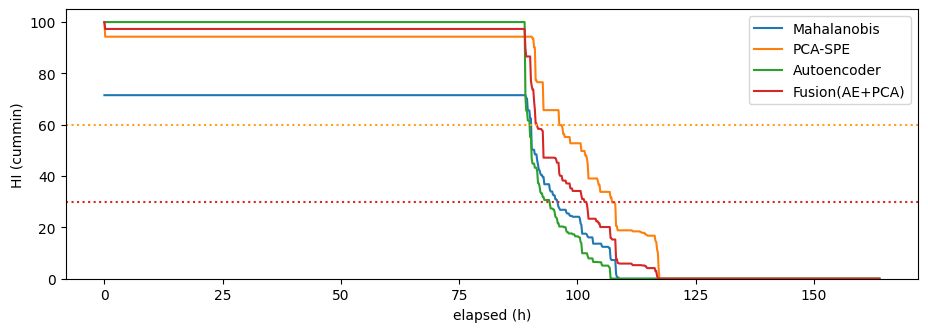

In [ ]:
# 베어링 1: 방법별 HI(단조 표시용 cummin) 비교
plt.figure(figsize=(11, 3.5))
for m in methods:
    r = res[res['bearing'] == 1]
    plt.plot(r['elapsed_h'], r[f'{m}|hi_mono'], label=m)
plt.axhline(60, ls=':', color='#ff9f1c'); plt.axhline(30, ls=':', color='#d62728')
plt.ylim(0, 105); plt.xlabel('elapsed (h)'); plt.ylabel('HI (cummin)'); plt.legend(); plt.show()

## 11. 저장 (서버에서 쓸 모델과 설정)
- `ims_ae.pt`: Autoencoder 가중치 (입력 차원 = 특징 수)
- `ims_anomaly_meta.json`: 사용한 특징 이름, **베어링별 정상 구간 평균/표준편차**, PCA 성분, 마할라노비스 행렬, **방법별 임계값**, HI 변환 상수, 신호 파라미터(fs, 회전수, 결함 주파수, 엔벨로프 대역)
- `ims_scores_4ch.parquet`: 모든 점수와 HI (대시보드 데모/검증용)

서버의 진동 워커가 새 파형에서 같은 특징을 뽑고, 같은 변환(부호 보존 로그 → 베어링별 z-score → 클리핑)을 적용해야 같은 점수가 나옵니다.

In [ ]:
torch.save(ae.state_dict(), BASE / 'models' / 'ims_ae.pt')

meta = {
    'feature_cols': feat_cols,
    'transform': {'slog': True, 'z_clip': Z_CLIP},
    'normal_frac': NORMAL_FRAC,
    'baseline': {str(b): {'mu': mu[b].tolist(), 'sd': sd[b].tolist()} for b in bearings},
    'ae': {'input_dim': D, 'latent': 4, 'threshold': thr['Autoencoder']},
    'pca': {'mean': pca.mean_.tolist(), 'components': pca.components_.tolist(), 'threshold': thr['PCA-SPE']},
    'maha': {'mu': mu0.tolist(), 'cov_inv': cov_inv.tolist(), 'threshold': thr['Mahalanobis']},
    'hi': {'r_max': R_MAX, 'warn': 60, 'crit': 30},
    'signal': {'fs': IMS_FS, 'shaft_hz': IMS_SHAFT, 'env_band': list(ENV_BAND),
               'fault_hz': {k: float(v) for k, v in IMS_FAULT.items()}},
}
json.dump(meta, open(BASE / 'models' / 'ims_anomaly_meta.json', 'w'), indent=1)
res.to_parquet(BASE / 'features' / 'ims_scores_4ch.parquet', index=False)
print(sorted(p.name for p in (BASE / 'models').iterdir()))

['ims_ae.pt', 'ims_anomaly_meta.json', 'rul_cnn_bilstm_fd001.pt', 'rul_meta_fd001.json']
